# Lab 7.3: Anchors, Ceteris Paribus Profiles and a Local Explanation Set

Run the cells from top to bottom. Sections 1 and 2 rebuild the customer table and the model from Lab 7.2 (same data, same seeds). Section 6 produces the five-decision explanation set for your Explanation Dossier.

Data: Online Retail II (Chen, 2012), UCI Machine Learning Repository, CC BY 4.0, https://doi.org/10.24432/C5CG6D.

## 1. Build the customer table

In [1]:
import os, zipfile, urllib.request, tempfile, warnings, itertools
from pathlib import Path
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

UCI = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
CUTOFF, HORIZON = pd.Timestamp("2011-06-09"), 183

def load_transactions():
    """Online Retail II (Chen, 2012; UCI, CC BY 4.0). Downloads about 45 MB once to a temporary
    folder and caches a compressed CSV there. Offline: put online_retail_II.xlsx next to this notebook."""
    cache = Path(tempfile.gettempdir()) / "xai-ch07"; cache.mkdir(exist_ok=True)
    csv = cache / "online_retail_II.csv.gz"
    if not csv.exists():
        xlsx = Path("online_retail_II.xlsx")
        if not xlsx.exists():
            xlsx = cache / "online_retail_II.xlsx"
            if not xlsx.exists():
                z = cache / "oretail.zip"; urllib.request.urlretrieve(UCI, z)
                zipfile.ZipFile(z).extractall(cache)
        sheets = pd.read_excel(xlsx, sheet_name=None, dtype={"Invoice": str, "StockCode": str})
        pd.concat(sheets.values(), ignore_index=True).to_csv(csv, index=False)
    d = pd.read_csv(csv, dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])
    d = d.dropna(subset=["Customer ID"]).copy()
    d["cid"] = d["Customer ID"].astype(int)
    d["value"] = d["Quantity"] * d["Price"]
    d["is_return"] = d["Invoice"].str.startswith("C")
    return d

def churn_table(d):
    """One row per customer who bought in the 12 months before the cutoff.
    churn = 1 if the customer places no order in the 183 days after the cutoff."""
    past = d[d.InvoiceDate < CUTOFF]
    future = d[(d.InvoiceDate >= CUTOFF) & (d.InvoiceDate < CUTOFF + pd.Timedelta(days=HORIZON)) & ~d.is_return]
    buys, rets = past[~past.is_return], past[past.is_return]
    year = buys[buys.InvoiceDate >= CUTOFF - pd.Timedelta(days=365)]
    active = np.sort(year.cid.unique())
    g, g12 = buys[buys.cid.isin(active)].groupby("cid"), year.groupby("cid")
    f = pd.DataFrame(index=pd.Index(active, name="cid"))
    f["recency_days"] = (CUTOFF - g.InvoiceDate.max()).dt.days
    f["tenure_days"] = (CUTOFF - g.InvoiceDate.min()).dt.days
    f["orders_12m"] = g12.Invoice.nunique()
    f["spend_12m"] = g12.value.sum().clip(lower=0)
    f["avg_order_value"] = f.spend_12m / f.orders_12m
    f["products_12m"] = g12.StockCode.nunique()
    q = year[year.InvoiceDate >= CUTOFF - pd.Timedelta(days=90)]
    f["orders_90d"] = q.groupby("cid").Invoice.nunique().reindex(f.index).fillna(0)
    rv = rets[rets.InvoiceDate >= CUTOFF - pd.Timedelta(days=365)].groupby("cid").value.sum().abs().reindex(f.index).fillna(0)
    f["return_share"] = (rv / (f.spend_12m + rv)).fillna(0)
    country = buys.groupby("cid").Country.agg(lambda s: s.mode().iloc[0])
    f["uk"] = (country.reindex(f.index) == "United Kingdom").astype(int)
    f["churn"] = (~f.index.isin(future.cid.unique())).astype(int)
    return f

d = load_transactions()
f = churn_table(d)
print("transactions with a customer ID:", len(d))
print("customers:", len(f), " churn rate: %.3f" % f.churn.mean())
f.head()

transactions with a customer ID: 824364
customers: 4335  churn rate: 0.427


,recency_days,tenure_days,orders_12m,spend_12m,avg_order_value,products_12m,orders_90d,return_share,uk,churn
cid,,,,,,,,,,
12346,141,541,2,77325.91,38662.9550,20,0.0,0.500619,1,1
12347,62,220,4,3146.75,786.6875,90,1.0,0.000000,0,0
12348,64,254,4,1709.40,427.3500,25,1.0,0.000000,0,0
12349,223,405,1,1402.62,1402.6200,55,0.0,0.000000,0,0
12350,126,126,1,334.40,334.4000,17,0.0,0.000000,0,1


## 2. Train the black box

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

X, y = f.drop(columns="churn"), f.churn
names = list(X.columns)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, random_state=0).fit(Xtr, ytr)
logit = LogisticRegression(max_iter=2000).fit(np.log1p(Xtr.clip(lower=0)), ytr)
print("test AUC, boosted trees:       %.3f" % roc_auc_score(yte, model.predict_proba(Xte)[:, 1]))
print("test AUC, logistic on log(1+x): %.3f" % roc_auc_score(yte, logit.predict_proba(np.log1p(Xte.clip(lower=0)))[:, 1]))
predict_proba = lambda a: model.predict_proba(pd.DataFrame(a, columns=names))

test AUC, boosted trees:       0.784
test AUC, logistic on log(1+x): 0.787


## 3. Anchors

An anchor is an if-then rule that, when it holds, keeps the model's prediction the same with high probability (precision), and applies to some share of customers (coverage). We use `anchor-exp`, the implementation by the authors of the method.

In [3]:
from anchor import anchor_tabular
anchor_exp = anchor_tabular.AnchorTabularExplainer(["stay", "churn"], names, Xtr.values, {})
predict = lambda a: model.predict(pd.DataFrame(a, columns=names))

def anchor_path(cid, threshold=0.95, seed=0):
    np.random.seed(seed)
    e = anchor_exp.explain_instance(X.loc[cid].values, predict, threshold=threshold)
    return pd.DataFrame([(" AND ".join(e.names()[:i + 1]), round(e.precision(i), 3), round(e.coverage(i), 3))
                         for i in range(len(e.names()))], columns=["rule so far", "precision", "coverage"])

for cid in [14203, 16027]:
    print("customer", cid, "predicted:", ["stay", "churn"][int(predict(X.loc[[cid]].values)[0])])
    display(anchor_path(cid))

customer 14203 predicted: churn


,rule so far,precision,coverage
0,recency_days > 212.75,0.686,0.242
1,recency_days > 212.75 AND orders_12m <= 1.00,0.909,0.163
2,recency_days > 212.75 AND orders_12m <= 1.00 A...,0.957,0.081


customer 16027 predicted: churn


,rule so far,precision,coverage
0,products_12m <= 16.00,0.499,0.266
1,products_12m <= 16.00 AND spend_12m <= 671.99,0.778,0.228
2,products_12m <= 16.00 AND spend_12m <= 671.99 ...,0.837,0.204
3,products_12m <= 16.00 AND spend_12m <= 671.99 ...,0.847,0.202


**Checkpoint 1.** For customer 14203 the anchor `recency_days > 212.75 AND orders_12m <= 1 AND products_12m <= 16` reaches precision about 0.96 with coverage about 0.08. For customer 16027 the search stops at about 0.85 precision: no short rule holds this prediction in place. That is information too: the customer sits near the decision boundary.

## 4. Do anchors depend on the seed?

In [4]:
for s in range(5):
    path = anchor_path(14203, seed=s)
    print(s, path.iloc[-1].tolist())

0 ['recency_days > 212.75 AND orders_12m <= 1.00 AND products_12m <= 16.00', np.float64(0.957), np.float64(0.081)]


1 ['recency_days > 212.75 AND orders_12m <= 1.00 AND tenure_days <= 364.00', np.float64(0.968), np.float64(0.114)]


2 ['recency_days > 212.75 AND orders_12m <= 1.00 AND tenure_days <= 364.00', np.float64(0.964), np.float64(0.113)]


3 ['recency_days > 212.75 AND orders_12m <= 1.00 AND tenure_days <= 364.00', np.float64(0.989), np.float64(0.114)]


4 ['recency_days > 212.75 AND orders_12m <= 1.00 AND tenure_days <= 364.00', np.float64(0.971), np.float64(0.114)]


**Checkpoint 2.** Compare the five final rules. Anchors are found by sampling too; note whether the rule, its precision or its coverage changes between seeds.

## 5. Ceteris paribus profiles

Change one feature of one customer over a grid, hold everything else fixed, and plot the model's output. This is the curve LIME approximates with a single slope.

recency_days: current 34.000; profile from 0.300 to 0.873


products_12m: current 5.000; profile from 0.281 to 0.538


return_share: current 0.192; profile from 0.250 to 0.511


orders_12m: current 5.000; profile from 0.089 to 0.764


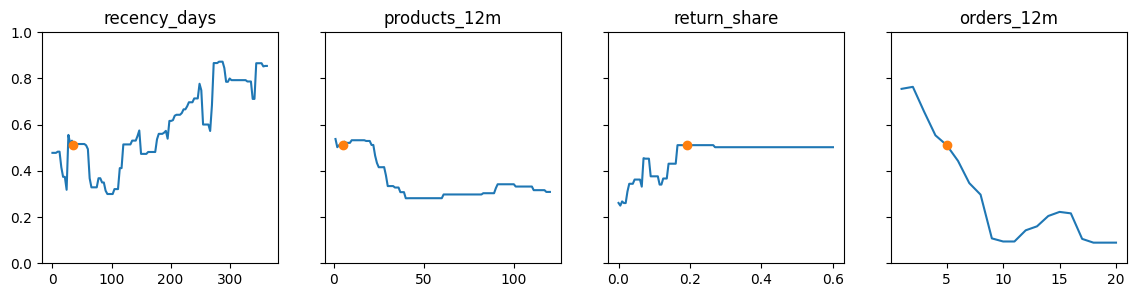

In [5]:
import matplotlib.pyplot as plt
def cp_profile(cid, feature, grid):
    Z = pd.concat([X.loc[[cid]]] * len(grid), ignore_index=True)
    Z[feature] = grid
    if feature == "orders_12m":
        Z["avg_order_value"] = Z.spend_12m / Z.orders_12m
    return model.predict_proba(Z)[:, 1]

grids = {"recency_days": np.arange(0, 365, 3), "products_12m": np.arange(1, 121),
         "return_share": np.linspace(0, 0.6, 121), "orders_12m": np.arange(1, 21)}
cid = 16027
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, (ft, g) in zip(axes, grids.items()):
    pr = cp_profile(cid, ft, g)
    ax.plot(g, pr); ax.plot(X.loc[cid, ft], model.predict_proba(X.loc[[cid]])[0, 1], "o")
    ax.set_title(ft); ax.set_ylim(0, 1)
    print(f"{ft}: current {X.loc[cid, ft]:.3f}; profile from {pr.min():.3f} to {pr.max():.3f}")
plt.show()

**Checkpoint 3.** For customer 16027 the profile on `return_share` drops from 0.511 at the current value (about 0.19) to about 0.25 when returns are near zero. LIME's discretized explanation gave `return_share > 0.01` a weight of only +0.024, because that bin lumps this customer with everyone who returned a little. The profile also shows that 0.19 lies outside the range where most customers are (check `Xtr.return_share.quantile(0.95)`).

In [6]:
print('95th percentile of return_share in training data: %.3f' % Xtr.return_share.quantile(0.95))

95th percentile of return_share in training data: 0.099


## 6. Your local explanation set (portfolio)

Pick five customers. For each, record the prediction, LIME's top three with their stability over 20 seeds, the anchor with precision and coverage, and one ceteris paribus finding. Replace the list below with your own choice and explain why you chose them (for example: two confident churn predictions, one near the threshold, one confident stay, one surprising case).

In [7]:
from lime.lime_tabular import LimeTabularExplainer
def lime_top3(cid, seed, n=2500):
    e = LimeTabularExplainer(Xtr.values, feature_names=names, discretize_continuous=True, random_state=seed
                             ).explain_instance(X.loc[cid].values, lambda a: model.predict_proba(pd.DataFrame(a, columns=names)),
                                                num_features=3, num_samples=n)
    return e.as_list(), [names[j] for j, _ in e.as_map()[1]], e.score

def jaccard(a, b):
    return len(set(a) & set(b)) / len(set(a) | set(b))

chosen = [14203, 16027, 17726, 14933, 12347]
rows = []
for cid in chosen:
    p = model.predict_proba(X.loc[[cid]])[0, 1]
    first, _, r2 = lime_top3(cid, 0)
    tops = [lime_top3(cid, s)[1] for s in range(20)]
    J = np.mean([jaccard(a, b) for a, b in itertools.combinations(tops, 2)])
    a = anchor_path(cid).iloc[-1]
    rows.append(dict(customer=cid, churn_prob=round(p, 3), lime_top3="; ".join(c for c, _ in first),
                     lime_R2=round(r2, 2), top3_jaccard=round(J, 2), anchor=a["rule so far"],
                     anchor_precision=a["precision"], anchor_coverage=a["coverage"]))
card = pd.DataFrame(rows)
card

,customer,churn_prob,lime_top3,lime_R2,top3_jaccard,anchor,anchor_precision,anchor_coverage
0,14203,0.680,recency_days > 212.75; orders_12m <= 1.00; pro...,0.26,0.67,recency_days > 212.75 AND orders_12m <= 1.00 A...,0.957,0.081
1,16027,0.511,orders_12m > 4.75; 31.00 < recency_days <= 106...,0.12,0.91,products_12m <= 16.00 AND spend_12m <= 671.99 ...,0.847,0.202
2,17726,0.741,orders_12m > 4.75; tenure_days > 495.00; order...,0.09,0.87,recency_days > 106.00 AND avg_order_value <= 1...,0.864,0.121
3,14933,0.842,recency_days > 212.75; spend_12m > 1625.27; pr...,0.29,0.80,recency_days > 212.75 AND products_12m <= 16.0...,0.975,0.061
4,12347,0.093,spend_12m > 1625.27; products_12m > 73.00; 31....,0.16,1.00,spend_12m > 1625.27 AND orders_90d > 0.00,0.979,0.192


**Checkpoint 4.** You have a table with one row per decision. Add, by hand, one sentence per customer that an agent could say aloud, and mark each sentence *safe to read* or *do not read* using the rule in the chapter: read a reason aloud only if it is stable across reruns, consistent with the anchor or the profile, and something the customer would recognize as true of themselves.

In [8]:
card.to_csv('local_explanation_set.csv', index=False); print('saved local_explanation_set.csv')

saved local_explanation_set.csv
